# Marketing Funnel & Conversion Performance Analysis

## Future Interns – Data Science & Analytics Task 3

This project analyzes marketing and lead funnel data to understand how users move through different stages of the conversion funnel.

### Objectives

- Analyze traffic-to-lead conversion
- Analyze lead-to-customer conversion
- Identify drop-off points at each funnel stage
- Compare performance across campaigns and advertisements
- Identify high-performing and low-performing campaigns
- Generate actionable recommendations to improve conversions

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Dataset/KAG_conversion_data.csv")

df.head()

,ad_id,xyz_campaign_id,fb_campaign_id,age,gender,interest,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion
0,708746,916,103916,30-34,M,15,7350,1,1.43,2,1
1,708749,916,103917,30-34,M,16,17861,2,1.82,2,0
2,708771,916,103920,30-34,M,20,693,0,0.00,1,0
3,708815,916,103928,30-34,M,28,4259,1,1.25,1,0
4,708818,916,103928,30-34,M,28,4133,1,1.29,1,1


In [2]:
df.shape

(1143, 11)

In [3]:
df.columns

Index(['ad_id', 'xyz_campaign_id', 'fb_campaign_id', 'age', 'gender',
       'interest', 'Impressions', 'Clicks', 'Spent', 'Total_Conversion',
       'Approved_Conversion'],
      dtype='str')

In [4]:
df.isnull().sum()

ad_id                  0
xyz_campaign_id        0
fb_campaign_id         0
age                    0
gender                 0
interest               0
Impressions            0
Clicks                 0
Spent                  0
Total_Conversion       0
Approved_Conversion    0
dtype: int64

In [5]:
df.dtypes

ad_id                    int64
xyz_campaign_id          int64
fb_campaign_id           int64
age                        str
gender                     str
interest                 int64
Impressions              int64
Clicks                   int64
Spent                  float64
Total_Conversion         int64
Approved_Conversion      int64
dtype: object

In [6]:
numeric_columns = [
    'Impressions',
    'Clicks',
    'Spent',
    'Total_Conversion',
    'Approved_Conversion'
]

df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')

df[numeric_columns].dtypes

Impressions              int64
Clicks                   int64
Spent                  float64
Total_Conversion         int64
Approved_Conversion      int64
dtype: object

In [7]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [8]:
df = df.drop_duplicates()

In [9]:
# Check for negative values
print("Negative Impressions:", (df['Impressions'] < 0).sum())
print("Negative Clicks:", (df['Clicks'] < 0).sum())
print("Negative Spent:", (df['Spent'] < 0).sum())
print("Negative Conversions:", (df['Total_Conversion'] < 0).sum())
print("Negative Approved Conversions:", (df['Approved_Conversion'] < 0).sum())

Negative Impressions: 0
Negative Clicks: 0
Negative Spent: 0
Negative Conversions: 0
Negative Approved Conversions: 0


In [10]:
total_impressions = df['Impressions'].sum()
total_clicks = df['Clicks'].sum()
total_leads = df['Total_Conversion'].sum()
total_customers = df['Approved_Conversion'].sum()

print("Total Impressions:", total_impressions)
print("Total Clicks:", total_clicks)
print("Total Leads:", total_leads)
print("Total Customers:", total_customers)

Total Impressions: 213434828
Total Clicks: 38165
Total Leads: 3264
Total Customers: 1079


In [11]:
traffic_to_click = (total_clicks / total_impressions) * 100
click_to_lead = (total_leads / total_clicks) * 100
lead_to_customer = (total_customers / total_leads) * 100
overall_conversion = (total_customers / total_impressions) * 100

print(f"Impression to Click Rate: {traffic_to_click:.2f}%")
print(f"Click to Lead Rate: {click_to_lead:.2f}%")
print(f"Lead to Customer Rate: {lead_to_customer:.2f}%")
print(f"Overall Conversion Rate: {overall_conversion:.4f}%")

Impression to Click Rate: 0.02%
Click to Lead Rate: 8.55%
Lead to Customer Rate: 33.06%
Overall Conversion Rate: 0.0005%


In [12]:
drop_impressions_clicks = total_impressions - total_clicks
drop_clicks_leads = total_clicks - total_leads
drop_leads_customers = total_leads - total_customers

print("Drop-off: Impressions → Clicks:", drop_impressions_clicks)
print("Drop-off: Clicks → Leads:", drop_clicks_leads)
print("Drop-off: Leads → Customers:", drop_leads_customers)

Drop-off: Impressions → Clicks: 213396663
Drop-off: Clicks → Leads: 34901
Drop-off: Leads → Customers: 2185


In [13]:
funnel_data = pd.DataFrame({
    'Stage': [
        'Impressions',
        'Clicks',
        'Leads',
        'Customers'
    ],
    'Count': [
        total_impressions,
        total_clicks,
        total_leads,
        total_customers
    ]
})

funnel_data

,Stage,Count
0,Impressions,213434828
1,Clicks,38165
2,Leads,3264
3,Customers,1079


In [14]:
campaign_summary = df.groupby('xyz_campaign_id').agg({
    'Impressions': 'sum',
    'Clicks': 'sum',
    'Spent': 'sum',
    'Total_Conversion': 'sum',
    'Approved_Conversion': 'sum'
}).reset_index()

campaign_summary

,xyz_campaign_id,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion
0,916,482925,113,149.710001,58,24
1,936,8128187,1984,2893.369999,537,183
2,1178,204823716,36068,55662.149959,2669,872


In [15]:
campaign_summary['Click_Rate'] = (
    campaign_summary['Clicks'] /
    campaign_summary['Impressions']
) * 100

campaign_summary['Lead_Conversion_Rate'] = (
    campaign_summary['Total_Conversion'] /
    campaign_summary['Clicks']
) * 100

campaign_summary['Customer_Conversion_Rate'] = (
    campaign_summary['Approved_Conversion'] /
    campaign_summary['Total_Conversion']
) * 100

campaign_summary

,xyz_campaign_id,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion,Click_Rate,Lead_Conversion_Rate,Customer_Conversion_Rate
0,916,482925,113,149.710001,58,24,0.023399,51.327434,41.379310
1,936,8128187,1984,2893.369999,537,183,0.024409,27.066532,34.078212
2,1178,204823716,36068,55662.149959,2669,872,0.017609,7.399911,32.671413


In [16]:
best_campaign = campaign_summary.sort_values(
    'Customer_Conversion_Rate',
    ascending=False
)

best_campaign

,xyz_campaign_id,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion,Click_Rate,Lead_Conversion_Rate,Customer_Conversion_Rate
0,916,482925,113,149.710001,58,24,0.023399,51.327434,41.379310
1,936,8128187,1984,2893.369999,537,183,0.024409,27.066532,34.078212
2,1178,204823716,36068,55662.149959,2669,872,0.017609,7.399911,32.671413


In [17]:
best_campaign.head(5)

,xyz_campaign_id,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion,Click_Rate,Lead_Conversion_Rate,Customer_Conversion_Rate
0,916,482925,113,149.710001,58,24,0.023399,51.327434,41.379310
1,936,8128187,1984,2893.369999,537,183,0.024409,27.066532,34.078212
2,1178,204823716,36068,55662.149959,2669,872,0.017609,7.399911,32.671413


In [18]:
top_customer_campaigns = campaign_summary.sort_values(
    'Approved_Conversion',
    ascending=False
)

top_customer_campaigns.head(5)

,xyz_campaign_id,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion,Click_Rate,Lead_Conversion_Rate,Customer_Conversion_Rate
2,1178,204823716,36068,55662.149959,2669,872,0.017609,7.399911,32.671413
1,936,8128187,1984,2893.369999,537,183,0.024409,27.066532,34.078212
0,916,482925,113,149.710001,58,24,0.023399,51.327434,41.379310


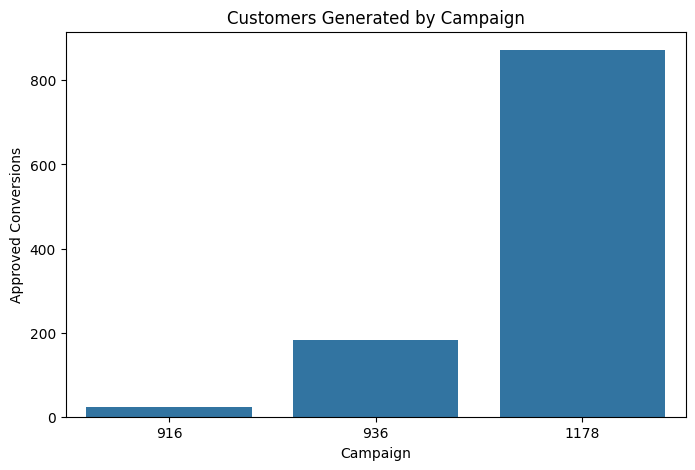

In [19]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=campaign_summary,
    x='xyz_campaign_id',
    y='Approved_Conversion'
)

plt.title('Customers Generated by Campaign')
plt.xlabel('Campaign')
plt.ylabel('Approved Conversions')
plt.show()

In [20]:
age_summary = df.groupby('age').agg({
    'Impressions': 'sum',
    'Clicks': 'sum',
    'Total_Conversion': 'sum',
    'Approved_Conversion': 'sum'
}).reset_index()

age_summary

,age,Impressions,Clicks,Total_Conversion,Approved_Conversion
0,30-34,67993019,9483,1431,494
1,35-39,42104644,7094,626,207
2,40-44,39604307,7736,523,170
3,45-49,63732858,13852,684,208


In [21]:
age_summary['Conversion_Rate'] = (
    age_summary['Approved_Conversion'] /
    age_summary['Clicks']
) * 100

age_summary

,age,Impressions,Clicks,Total_Conversion,Approved_Conversion,Conversion_Rate
0,30-34,67993019,9483,1431,494,5.209322
1,35-39,42104644,7094,626,207,2.917959
2,40-44,39604307,7736,523,170,2.197518
3,45-49,63732858,13852,684,208,1.501588


In [22]:
gender_summary = df.groupby('gender').agg({
    'Impressions': 'sum',
    'Clicks': 'sum',
    'Total_Conversion': 'sum',
    'Approved_Conversion': 'sum'
}).reset_index()

gender_summary

,gender,Impressions,Clicks,Total_Conversion,Approved_Conversion
0,F,114862847,23878,1644,495
1,M,98571981,14287,1620,584


In [23]:
gender_summary['Conversion_Rate'] = (
    gender_summary['Approved_Conversion'] /
    gender_summary['Clicks']
) * 100

gender_summary

,gender,Impressions,Clicks,Total_Conversion,Approved_Conversion,Conversion_Rate
0,F,114862847,23878,1644,495,2.073038
1,M,98571981,14287,1620,584,4.087632


In [24]:
interest_summary = df.groupby('interest').agg({
    'Impressions': 'sum',
    'Clicks': 'sum',
    'Total_Conversion': 'sum',
    'Approved_Conversion': 'sum'
}).reset_index()

interest_summary['Conversion_Rate'] = (
    interest_summary['Approved_Conversion'] /
    interest_summary['Clicks']
) * 100

interest_summary.head(10)

,interest,Impressions,Clicks,Total_Conversion,Approved_Conversion,Conversion_Rate
0,2,1727646,311,40,19,6.109325
1,7,2612839,410,59,19,4.634146
2,10,17989844,3317,269,91,2.743443
3,15,10745856,1609,195,63,3.915475
4,16,31809524,5144,411,141,2.741058
5,18,8646488,1524,85,33,2.165354
6,19,6083217,1188,97,33,2.777778
7,20,6899907,1234,129,47,3.808752
8,21,2833321,512,70,27,5.273438
9,22,3965401,717,50,12,1.673640


In [25]:
campaign_summary['CPC'] = (
    campaign_summary['Spent'] /
    campaign_summary['Clicks']
)

campaign_summary

,xyz_campaign_id,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion,Click_Rate,Lead_Conversion_Rate,Customer_Conversion_Rate,CPC
0,916,482925,113,149.710001,58,24,0.023399,51.327434,41.379310,1.324867
1,936,8128187,1984,2893.369999,537,183,0.024409,27.066532,34.078212,1.458352
2,1178,204823716,36068,55662.149959,2669,872,0.017609,7.399911,32.671413,1.543256


In [26]:
campaign_summary['Cost_Per_Lead'] = (
    campaign_summary['Spent'] /
    campaign_summary['Total_Conversion']
)

campaign_summary

,xyz_campaign_id,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion,Click_Rate,Lead_Conversion_Rate,Customer_Conversion_Rate,CPC,Cost_Per_Lead
0,916,482925,113,149.710001,58,24,0.023399,51.327434,41.379310,1.324867,2.581207
1,936,8128187,1984,2893.369999,537,183,0.024409,27.066532,34.078212,1.458352,5.388026
2,1178,204823716,36068,55662.149959,2669,872,0.017609,7.399911,32.671413,1.543256,20.855058


In [27]:
campaign_summary['Cost_Per_Customer'] = (
    campaign_summary['Spent'] /
    campaign_summary['Approved_Conversion']
)

campaign_summary

,xyz_campaign_id,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion,Click_Rate,Lead_Conversion_Rate,Customer_Conversion_Rate,CPC,Cost_Per_Lead,Cost_Per_Customer
0,916,482925,113,149.710001,58,24,0.023399,51.327434,41.379310,1.324867,2.581207,6.237917
1,936,8128187,1984,2893.369999,537,183,0.024409,27.066532,34.078212,1.458352,5.388026,15.810765
2,1178,204823716,36068,55662.149959,2669,872,0.017609,7.399911,32.671413,1.543256,20.855058,63.832741


In [28]:
campaign_summary.sort_values(
    'Cost_Per_Customer',
    ascending=True
).head(5)

,xyz_campaign_id,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion,Click_Rate,Lead_Conversion_Rate,Customer_Conversion_Rate,CPC,Cost_Per_Lead,Cost_Per_Customer
0,916,482925,113,149.710001,58,24,0.023399,51.327434,41.379310,1.324867,2.581207,6.237917
1,936,8128187,1984,2893.369999,537,183,0.024409,27.066532,34.078212,1.458352,5.388026,15.810765
2,1178,204823716,36068,55662.149959,2669,872,0.017609,7.399911,32.671413,1.543256,20.855058,63.832741


In [29]:
campaign_performance = campaign_summary[
    [
        'xyz_campaign_id',
        'Impressions',
        'Clicks',
        'Total_Conversion',
        'Approved_Conversion',
        'Spent',
        'Click_Rate',
        'Lead_Conversion_Rate',
        'Customer_Conversion_Rate',
        'CPC',
        'Cost_Per_Lead',
        'Cost_Per_Customer'
    ]
]

campaign_performance

,xyz_campaign_id,Impressions,Clicks,Total_Conversion,Approved_Conversion,Spent,Click_Rate,Lead_Conversion_Rate,Customer_Conversion_Rate,CPC,Cost_Per_Lead,Cost_Per_Customer
0,916,482925,113,58,24,149.710001,0.023399,51.327434,41.379310,1.324867,2.581207,6.237917
1,936,8128187,1984,537,183,2893.369999,0.024409,27.066532,34.078212,1.458352,5.388026,15.810765
2,1178,204823716,36068,2669,872,55662.149959,0.017609,7.399911,32.671413,1.543256,20.855058,63.832741


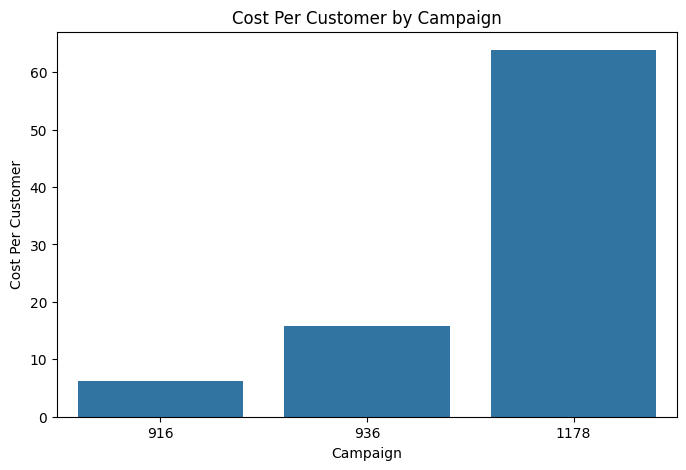

In [30]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=campaign_summary,
    x='xyz_campaign_id',
    y='Cost_Per_Customer'
)

plt.title('Cost Per Customer by Campaign')
plt.xlabel('Campaign')
plt.ylabel('Cost Per Customer')
plt.show()

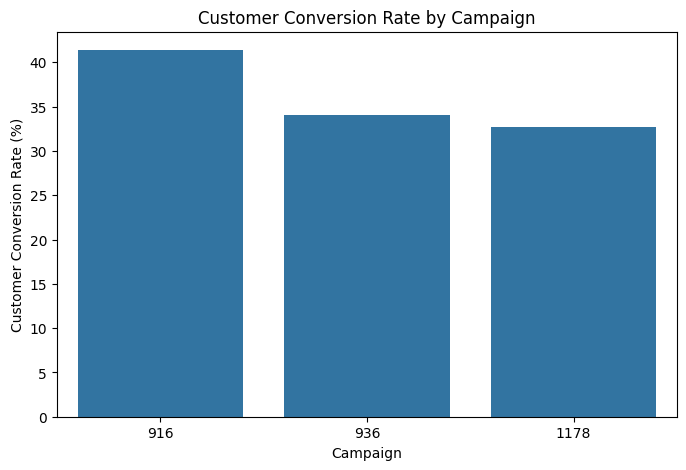

In [31]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=campaign_summary,
    x='xyz_campaign_id',
    y='Customer_Conversion_Rate'
)

plt.title('Customer Conversion Rate by Campaign')
plt.xlabel('Campaign')
plt.ylabel('Customer Conversion Rate (%)')
plt.show()

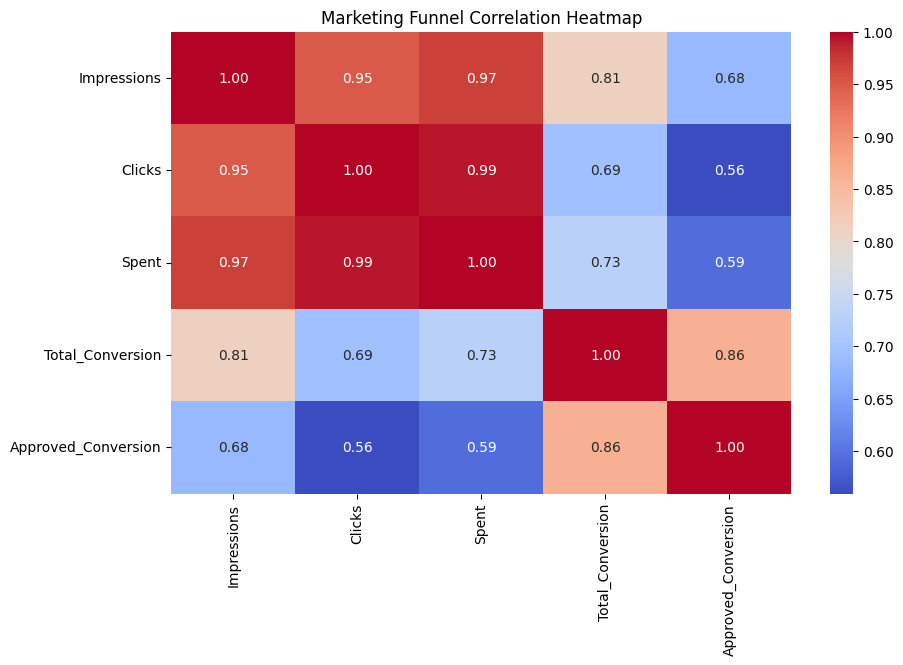

In [32]:
plt.figure(figsize=(10,6))

corr = df[
    [
        'Impressions',
        'Clicks',
        'Spent',
        'Total_Conversion',
        'Approved_Conversion'
    ]
].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Marketing Funnel Correlation Heatmap')
plt.show()

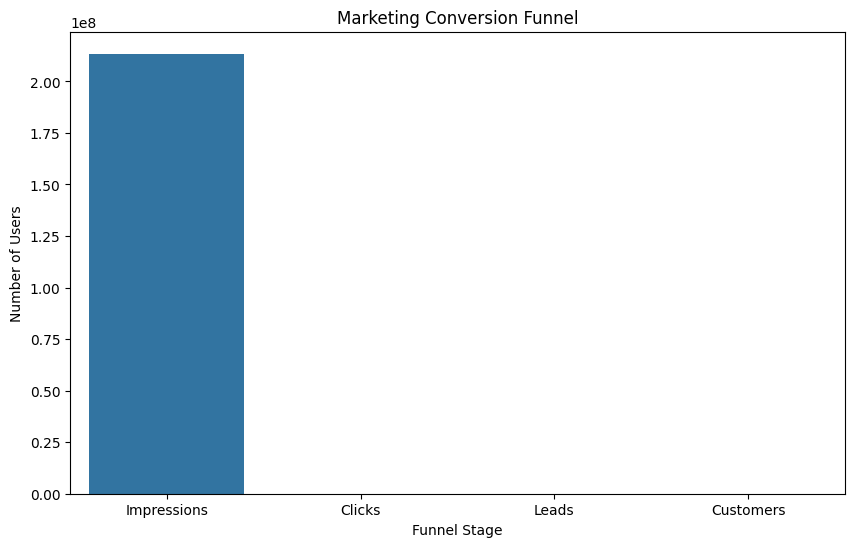

In [33]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=funnel_data,
    x='Stage',
    y='Count'
)

plt.title('Marketing Conversion Funnel')
plt.xlabel('Funnel Stage')
plt.ylabel('Number of Users')
plt.xticks(rotation=0)

plt.show()

In [41]:
df.to_csv(
    "KAG_conversion_data.csv",
    index=False
)

## Key Findings

### Funnel Performance
- The marketing funnel shows a significant drop-off from impressions to clicks.
- Further drop-offs occur as users move from clicks to leads and from leads to approved customers.
- The overall conversion rate indicates that only a small portion of the initial traffic becomes customers.

### Campaign Performance
- Campaigns differ in their ability to generate clicks, leads, and customers.
- The best-performing campaign should be evaluated using both conversion rate and customer acquisition cost.
- High customer volume does not always mean high efficiency.

### Customer Targeting
- Conversion performance varies across age groups and genders.
- Different interest groups show different levels of engagement and conversion.

### Cost Efficiency
- CPC, Cost Per Lead, and Cost Per Customer help identify campaigns that generate conversions efficiently.
- Campaigns with lower Cost Per Customer are more cost-effective for customer acquisition.

### Recommendations
- Optimize the stage with the highest funnel drop-off.
- Increase investment in high-converting and cost-efficient campaigns.
- Review campaigns with high spending but low customer conversion.
- Use high-performing audience segments for targeted marketing.
- Continuously monitor conversion rates and acquisition costs.

In [48]:
df.to_csv(
    "Dataset/Cleaned_Marketing_Funnel_Data.csv",
    index=False
)

print("Cleaned CSV created successfully!")

Cleaned CSV created successfully!


In [49]:
import os

print(os.path.exists("Dataset/Cleaned_Marketing_Funnel_Data.csv"))

True


In [50]:
pd.read_csv("Dataset/Cleaned_Marketing_Funnel_Data.csv").head()

,ad_id,xyz_campaign_id,fb_campaign_id,age,gender,interest,Impressions,Clicks,Spent,Total_Conversion,Approved_Conversion
0,708746,916,103916,30-34,M,15,7350,1,1.43,2,1
1,708749,916,103917,30-34,M,16,17861,2,1.82,2,0
2,708771,916,103920,30-34,M,20,693,0,0.00,1,0
3,708815,916,103928,30-34,M,28,4259,1,1.25,1,0
4,708818,916,103928,30-34,M,28,4133,1,1.29,1,1


In [52]:
df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric,
    errors='coerce'
)

In [53]:
df[numeric_columns].isnull().sum()

Impressions            0
Clicks                 0
Spent                  0
Total_Conversion       0
Approved_Conversion    0
dtype: int64